# AIDA 2156 Final Project – 04 Outliers, Feature Relationships and Sensitivity

**Data version 2** (`shared/synthetic-data/`): the official cleaned requests (cleaning version 1.1), with notebook 02's working calendar and notebook 03's comparisons. The answer key is not used.

**Question:** Do the findings of notebooks 02 and 03 hold when reasonable measurement and population choices change — in particular how after-hours submissions are handled and whether requests unfinished at the extract are included? Sections A and B first look at unusually long and short requests and at which workflow measures move together.

**Reference analysis.** Notebooks 02 and 03 exactly as run: working time (Monday–Friday, 08:00–16:30, excluding the simulated closure dates), so an after-hours submission starts counting at the next working moment; the 4,319 completed requests; and the 13 contrasts with 95% intervals from 2,000 employee resamples (seed 2026), with notebook 03's weights, workload cutoffs and rules. Part 1 reproduces these numbers exactly before any alternative is computed.

**Alternatives, fixed before any of their results are computed.** In the cleaned records only submissions happen outside working hours (656 of 4,364, 15.0%); every later workflow event falls within them. Each alternative changes one kind of thing:

| Scenario | What changes | Kind of change |
|:---|:---|:---|
| H1 Elapsed calendar time | Time is counted from the actual submission, through nights, weekends and closures (the requester's wait), in calendar days | Measurement |
| H2 Weekdays-only calendar | Monday–Friday 08:00–16:30 as before, but closure dates count as working days | Calendar |
| H3 Working-hours submissions only | After-hours submissions are left out | Population |
| H4 Narrower after-hours label | Only weekend and closure-date submissions count as after-hours; weekday submissions outside 08:00–16:30 count as working-hours submissions | Classification (after-hours contrasts only) |
| U1 Unfinished, time so far | The 45 unfinished requests are added with their working time up to the extract (29 Sep 2026, 17:00), a lower bound on their eventual time | Population |
| U2 Unfinished, longest | The 45 are added as longer than every completed request | Population |
| O1 Without the long tail | The requests above notebook 02's Tukey fence (11.68 working-day equivalents) are left out | Population |

**Rules for the unfinished requests.** For percentiles of all requests (completed and unfinished), U1 and U2 are bounds: the eventual value lies between them. Under U2 a percentile that falls among the unfinished requests is reported as "above the longest completed request". For contrasts, U1 and U2 are sensitivity scenarios, not bounds, because the unfinished requests may be spread unevenly between the compared groups. Under U2 every unfinished request is given one value that exceeds both the longest completed duration and the longest time so far of any unfinished request (the larger of the two plus one working-day equivalent), so it is longer than every completed request and consistent with every unfinished request's observed lower bound, and medians stay defined. U1 stage times are working time accumulated up to the extract, a different quantity from the stage shares of completed requests.

**Rules for the contrasts.** Each scenario uses notebook 03's 13 contrasts, estimators and bootstrap (2,000 employee resamples, seed 2026, intervals withheld when more than 1% of resamples are invalid). Workload cutoffs stay at notebook 03's values; stratum weights are the strata's shares of the scenario's own requests. Because those weights follow the scenario's population, a weighted contrast that differs from the reference can reflect both changed results within strata and a changed mix of strata; each scenario's strata, weights and coverage are therefore reported. A contrast that a scenario removes (the after-hours contrasts under H3) is "not applicable"; one whose groups both exist but no stratum has at least five requests on each side is "not estimable", with no estimate or interval.

**What counts as a change, fixed now.** For each contrast, three things are reported separately: whether the point estimate changes direction, how much it changes, and whether the interval's relation to zero changes (excludes zero ↔ includes zero). The full task-type ordering is reported; a swap between task types whose reference medians differ by less than 0.25 working-day equivalents is reported as a small swap, separately from changes that affect a written finding. Every written finding of notebooks 02 and 03 then gets one label: **stable** (no change in any applicable scenario), **depends on scenario** (named), **not applicable** (the scenario removes it) or **not comparable** (H1 sizes are in calendar days, so only direction and ordering are compared). Intervals are descriptive: no p-values are calculated and no difference is called significant.

All results describe generated data; patterns are associations, not causes.

In [1]:
import hashlib
import json
from datetime import datetime, time, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = Path("../figures")

read = lambda path: pd.read_csv(path, dtype=str, keep_default_na=False)
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()

requests = read(SD / "cleaning/output/requests_cleaned.csv")
cleaning_info = json.loads((SD / "cleaning/output/requests_cleaned_info.json").read_text())
assert sha(SD / "cleaning/output/requests_cleaned.csv") == cleaning_info["output_sha256"], \
    "The cleaned file doesn't match its cleaning record"

# Notebook 02's working calendar; the generator must be unchanged since then
calendar = json.loads((OUTPUT_DIR / "working_calendar.json").read_text())
assert sha(SD / "requests/generate_requests.py") == calendar["generator_sha256"], \
    "The generator has changed since notebook 02 saved the working calendar"
CLOSURES = {pd.Timestamp(d).date() for d in calendar["closure_dates"]}
DAY_START, DAY_END = time.fromisoformat(calendar["day_start"]), time.fromisoformat(calendar["day_end"])
DAY_HOURS = calendar["day_hours"]
EXTRACT_AT = pd.Timestamp(calendar["extract_at"])

# Inputs from notebooks 02 and 03 that this notebook must reproduce
inputs_03 = json.loads((OUTPUT_DIR / "analysis_inputs_03.json").read_text())
assert inputs_03["inputs_sha256"]["processing_times_completed.csv (notebook 02)"] == sha(OUTPUT_DIR / "processing_times_completed.csv")
assert inputs_03["inputs_sha256"]["working_calendar.json (notebook 02)"] == sha(OUTPUT_DIR / "working_calendar.json")
completed_02 = pd.read_csv(OUTPUT_DIR / "processing_times_completed.csv")
summary_02 = pd.read_csv(OUTPUT_DIR / "processing_time_summary.csv", index_col=0)
unfinished_02 = pd.read_csv(OUTPUT_DIR / "unfinished_requests.csv")
intervals_03 = pd.read_csv(OUTPUT_DIR / "contrast_intervals.csv")

TIME_COLUMNS = ["submitted_at", "info_complete_at", "assigned_at", "team_completed_at", "completion_confirmed_at"]
for c in TIME_COLUMNS:
    requests[c] = pd.to_datetime(requests[c].replace("", None), format="%Y-%m-%dT%H:%M")


def working_hours(start, end, closures=CLOSURES):
    # Notebook 02's working-time function, with the closure dates as a parameter (H2 passes an empty set)
    if pd.isna(start) or pd.isna(end):
        return np.nan
    if end < start:
        raise ValueError(f"End precedes start: {start} → {end}")
    if end == start:
        return 0.0
    total, day = 0.0, start.date()
    while day <= end.date():
        if day.weekday() < 5 and day not in closures:
            open_, close = datetime.combine(day, DAY_START), datetime.combine(day, DAY_END)
            total += max((min(end, close) - max(start, open_)).total_seconds(), 0) / 3600
        day += timedelta(days=1)
    return total


# Notebook 02's hand-made tests, plus the same closure case with closures counted as working days (H2)
T = pd.Timestamp
tests = pd.DataFrame([
    ("same working day", T("2026-03-03 09:00"), T("2026-03-03 11:30"), CLOSURES, 2.5),
    ("overnight", T("2026-03-03 15:30"), T("2026-03-04 09:00"), CLOSURES, 2.0),
    ("over a weekend", T("2026-03-06 16:00"), T("2026-03-09 08:30"), CLOSURES, 1.0),
    ("after-hours submission", T("2026-03-06 21:00"), T("2026-03-09 10:00"), CLOSURES, 2.0),
    ("over a simulated closure date (Fri 3 Apr 2026)", T("2026-04-02 16:00"), T("2026-04-06 09:00"), CLOSURES, 1.5),
    ("the same, closure counted as a working day (H2)", T("2026-04-02 16:00"), T("2026-04-06 09:00"), set(), 10.0),
    ("whole working day", T("2026-03-03 08:00"), T("2026-03-03 16:30"), CLOSURES, DAY_HOURS),
    ("start equals end", T("2026-03-03 10:00"), T("2026-03-03 10:00"), CLOSURES, 0.0),
], columns=["case", "start", "end", "closures", "expected_hours"])
assert T("2026-04-03").date() in CLOSURES
tests["calculated_hours"] = [working_hours(s, e, c) for s, e, c in zip(tests["start"], tests["end"], tests["closures"])]
assert np.isclose(tests["calculated_hours"], tests["expected_hours"]).all(), "The working-time function failed a test"

# Every workflow event other than submission falls inside working hours, as this notebook's design assumes
def outside_hours(t):
    t = t.dropna()
    return int(((t.dt.weekday >= 5) | t.dt.date.isin(CLOSURES) | ~t.dt.time.between(DAY_START, DAY_END, inclusive="both")).sum())
after_hours_events = {c: outside_hours(requests[c]) for c in TIME_COLUMNS}
assert all(v == 0 for c, v in after_hours_events.items() if c != "submitted_at"), "A later workflow event falls outside working hours"

print(f"Data version {DATA_VERSION}; cleaning version {cleaning_info['cleaning_version']}; extract {EXTRACT_AT:%Y-%m-%d %H:%M}")
print(f"{len(requests):,} cleaned requests; working-time function passes {len(tests)} hand-made tests (including H2's calendar)")
print("Events outside working hours, by timestamp:", after_hours_events)

Data version 2; cleaning version 1.1; extract 2026-09-29 17:00
4,364 cleaned requests; working-time function passes 8 hand-made tests (including H2's calendar)
Events outside working hours, by timestamp: {'submitted_at': 656, 'info_complete_at': 0, 'assigned_at': 0, 'team_completed_at': 0, 'completion_confirmed_at': 0}


## The reference, reproduced

The cell below rebuilds every request's durations and notebook 03's variables from the cleaned requests, using notebook 02's and notebook 03's rules unchanged: stage times and processing time in working-day equivalents, elapsed calendar days, working time so far for the unfinished requests, workload at assignment and its groups, the after-hours label and the intake channel. It then rebuilds notebook 03's 13 contrasts and their employee-bootstrap intervals, written as functions so every scenario can reuse them.

Before anything else is computed, the rebuilt values must match the saved outputs of notebooks 02 and 03, which the later sections use as the reference:

- each completed request's processing time, stage times and calendar days, and each unfinished request's time so far;
- notebook 02's overall summaries in working-day equivalents and calendar days (median, mean, quartiles, IQR, 90th percentile, longest, skew, Tukey fence and the number and share above it), its summaries by task type, its stage summary and its stage shares by task type;
- every contrast's point estimate, interval, number of valid resamples and whether its interval was withheld.

Counts must match exactly; other values are compared to within 1e-9, to allow only for floating-point rounding.

In [2]:
STAGES = ["info_check_h", "assignment_wait_h", "team_processing_h"]
TASK_ORDER = ["payroll_setup", "system_access", "workplace_access", "equipment_setup", "orientation_scheduling"]
r = requests.copy()
finished = r["team_completed_at"].notna()
all_stage_times = r[["submitted_at", "info_complete_at", "assigned_at", "team_completed_at"]].notna().all(axis=1)
r["group"] = np.select([finished & all_stage_times, ~finished], ["completed", "unfinished at extract"], default="other")
assert (r["group"] != "other").all(), "Every request should be completed with all stage times, or unfinished"


def durations(frame, closures=CLOSURES):
    # Stage, processing and time-so-far working durations under a closure calendar, in hours and working-day equivalents
    out = pd.DataFrame(index=frame.index)
    out["info_check_h"] = [working_hours(a, b, closures) for a, b in zip(frame["submitted_at"], frame["info_complete_at"])]
    out["assignment_wait_h"] = [working_hours(a, b, closures) for a, b in zip(frame["info_complete_at"], frame["assigned_at"])]
    out["team_processing_h"] = [working_hours(a, b, closures) for a, b in zip(frame["assigned_at"], frame["team_completed_at"])]
    out["processing_days"] = [working_hours(a, b, closures) / DAY_HOURS for a, b in zip(frame["submitted_at"], frame["team_completed_at"])]
    out["days_so_far"] = [working_hours(a, EXTRACT_AT, closures) / DAY_HOURS for a in frame["submitted_at"]]
    out["elapsed_calendar_days"] = (frame["team_completed_at"] - frame["submitted_at"]).dt.total_seconds() / 86400
    out["calendar_days_so_far"] = (EXTRACT_AT - frame["submitted_at"]).dt.total_seconds() / 86400
    return out


r = r.join(durations(r))
r["processing_h"] = r["processing_days"] * DAY_HOURS
STAGE_NAMES = {"info_check_h": "information check", "assignment_wait_h": "assignment wait", "team_processing_h": "team processing"}


def describe(values):
    # Notebook 02's summary of a duration
    values = values.dropna()
    q1, med, q3, p90 = values.quantile([0.25, 0.5, 0.75, 0.9])
    fence = q3 + 1.5 * (q3 - q1)
    return pd.Series({"requests": int(values.count()), "median": med, "mean": values.mean(), "q1": q1, "q3": q3,
                      "iqr": q3 - q1, "p90": p90, "max": values.max(), "skew": values.skew(), "tukey_fence": fence,
                      "unusually_long": int((values > fence).sum()), "unusually_long_%": 100 * (values > fence).mean()})


def stage_table(frame):
    # Notebook 02's stage summary: median and mean stage time, and each stage's share of total working time
    total = frame["processing_h"].sum()
    rows = {name: {"requests": len(frame), "median_days": (frame[col] / DAY_HOURS).median(),
                   "mean_days": (frame[col] / DAY_HOURS).mean(), "share_of_total_%": 100 * frame[col].sum() / total}
            for col, name in STAGE_NAMES.items()}
    return pd.DataFrame(rows).T


# Notebook 03's variables, unchanged
assigned = r[r["assigned_at"].notna()]
workload = {}
for team, g in assigned.groupby("responsible_team"):
    a = g["assigned_at"].to_numpy()
    done = g["team_completed_at"].fillna(pd.Timestamp.max).to_numpy()
    for rid, t in zip(g["request_id"], a):
        workload[rid] = int(((a < t) & (done > t)).sum())
r["workload_at_assignment"] = r["request_id"].map(workload)
r["intake_channel"] = r["intake_channel"].replace("", "unknown")
r["info_issue_at_intake"] = r["info_issue_at_intake"].map({"True": True, "False": False})
s = r["submitted_at"]
in_hours = s.dt.time.between(DAY_START, DAY_END, inclusive="both")
r["after_hours"] = (s.dt.weekday >= 5) | s.dt.date.isin(CLOSURES) | ~in_hours
r["after_hours_narrow"] = (s.dt.weekday >= 5) | s.dt.date.isin(CLOSURES)           # H4's label

# The completed requests, in notebook 02's row order (the bootstrap draws depend on it)
completed = r.set_index("request_id").loc[completed_02["request_id"]].reset_index()
Q1, Q3 = completed["workload_at_assignment"].quantile([0.25, 0.75])                # notebook 03's cutoffs, kept for every scenario
group_workload = lambda w: np.select([w <= Q1, w >= Q3], ["low", "high"], default="middle").astype(object)
r["workload_group"] = np.where(r["workload_at_assignment"].isna(), "not assigned", group_workload(r["workload_at_assignment"]))
completed["workload_group"] = group_workload(completed["workload_at_assignment"])
unfinished = r[r["group"] == "unfinished at extract"].copy()

# Reproduction of notebook 02
close = lambda a, b: np.allclose(np.asarray(a, dtype=float), np.asarray(b, dtype=float), rtol=0, atol=1e-9)
REPRO_02 = (completed["request_id"].tolist() == completed_02["request_id"].tolist()
            and all(close(completed[c], completed_02[c]) for c in ["processing_days", "elapsed_calendar_days"] + STAGES)
            and (completed["task_type"].to_numpy() == completed_02["task_type"].to_numpy()).all()
            and set(unfinished["request_id"]) == set(unfinished_02["request_id"])
            and close(unfinished.set_index("request_id").loc[unfinished_02["request_id"], "days_so_far"], unfinished_02["days_so_far"]))
ref_summary = pd.DataFrame({"working-day equivalents": describe(completed["processing_days"]),
                            "elapsed calendar days": describe(completed["elapsed_calendar_days"])}).T
ref_by_task = completed.groupby("task_type")["processing_days"].apply(describe).unstack().reindex(TASK_ORDER)
ref_stages = stage_table(completed)
ref_shares_by_task = pd.DataFrame({t: stage_table(completed[completed["task_type"] == t])["share_of_total_%"] for t in TASK_ORDER}).T
by_task_02 = pd.read_csv(OUTPUT_DIR / "processing_time_by_task_type.csv", index_col=0)
stages_02 = pd.read_csv(OUTPUT_DIR / "stage_summary.csv", index_col=0)
shares_02 = pd.read_csv(OUTPUT_DIR / "stage_shares_by_task_type.csv", index_col=0)
COUNTS = ["requests", "unusually_long"]
REPRO_02 = REPRO_02 and (
    (ref_summary[COUNTS].astype(int).to_numpy() == summary_02[COUNTS].to_numpy()).all()
    and close(ref_summary.drop(columns=COUNTS), summary_02[ref_summary.drop(columns=COUNTS).columns])
    and (ref_by_task["requests"].astype(int).to_numpy() == by_task_02["requests"].to_numpy()).all()
    and close(ref_by_task[["median", "mean", "q1", "q3", "iqr", "p90", "max", "skew"]],
              by_task_02[["median", "mean", "q1", "q3", "iqr", "p90", "max", "skew"]])
    and (ref_stages["requests"].astype(int).to_numpy() == stages_02["requests"].to_numpy()).all()
    and close(ref_stages[["median_days", "mean_days", "share_of_total_%"]], stages_02[["median_days", "mean_days", "share_of_total_%"]])
    and close(ref_shares_by_task, shares_02[list(STAGE_NAMES.values())]))
FENCE = ref_summary.loc["working-day equivalents", "tukey_fence"]
assert REPRO_02, "The rebuilt durations or summaries do not reproduce notebook 02"

# Notebook 03's contrasts and bootstrap, as functions of a scenario's requests and times
MIN_PER_SIDE, B, MAX_INVALID_SHARE, SEED = 5, 2000, 0.01, 2026
TASKS = ["equipment_setup", "system_access", "workplace_access", "orientation_scheduling"]
CONTRASTS = (
    [(f"{t} - payroll_setup", "task_type", t, "payroll_setup", None) for t in TASKS]
    + [("information issue - none", "info_issue_at_intake", True, False, None),
       ("high - low workload", "workload_group", "high", "low", None),
       ("high - low workload, within task type", "workload_group", "high", "low", ["task_type"]),
       ("after-hours - working hours", "after_hours", True, False, None),
       ("after-hours - working hours, within information issue x task type", "after_hours", True, False,
        ["info_issue_at_intake", "task_type"]),
       ("phone - web form", "intake_channel", "phone", "web_form", None),
       ("phone - web form, within information issue", "intake_channel", "phone", "web_form", ["info_issue_at_intake"]),
       ("email - web form", "intake_channel", "email", "web_form", None),
       ("email - web form, within information issue", "intake_channel", "email", "web_form", ["info_issue_at_intake"])])


def make_plans(df):
    # Notebook 03's contrast plans on one scenario's requests: groups, supported strata and weights
    plans = []
    for label, col, comp, ref, strata in CONTRASTS:
        comp_mask, ref_mask = (df[col] == comp).to_numpy(), (df[col] == ref).to_numpy()
        applicable = bool(comp_mask.any() and ref_mask.any())
        plan = {"label": label, "comp": comp_mask, "ref": ref_mask, "strata": None, "applicable": applicable,
                "reason": "" if applicable else "a compared group is empty in this scenario"}
        if strata and applicable:
            key = df[strata].astype(str).agg(" | ".join, axis=1).to_numpy()
            cells = [(k, (key == k).sum() / len(df)) for k in sorted(set(key))
                     if (comp_mask & (key == k)).sum() >= MIN_PER_SIDE and (ref_mask & (key == k)).sum() >= MIN_PER_SIDE]
            if not cells:                                            # both groups exist, but no stratum supports a comparison
                plan.update({"applicable": False, "reason": f"no stratum has at least {MIN_PER_SIDE} requests on each side"})
            else:
                weights = np.array([w for _, w in cells], dtype=float)
                plan.update({"strata": [k for k, _ in cells], "key": key, "weights": weights / weights.sum(),
                             "coverage_%": 100 * weights.sum(), "stratum_weights": dict(zip([k for k, _ in cells], weights / weights.sum()))})
        plans.append(plan)
    return plans


def estimate(plan, y, idx):
    yy, comp, ref = y[idx], plan["comp"][idx], plan["ref"][idx]
    if plan["strata"] is None:
        if not comp.any() or not ref.any():
            return np.nan
        return np.median(yy[comp]) - np.median(yy[ref])
    key = plan["key"][idx]
    diffs = []
    for k in plan["strata"]:
        c, r_ = comp & (key == k), ref & (key == k)
        if not c.any() or not r_.any():
            return np.nan
        diffs.append(np.median(yy[c]) - np.median(yy[r_]))
    return float(np.dot(plan["weights"], diffs))


def contrast_table(df, y):
    # Point estimates and 95% employee-bootstrap intervals for the 13 contrasts on one scenario
    plans = make_plans(df)
    emp_rows = df.groupby("employee_id").indices
    employees = np.array(sorted(emp_rows))
    rng = np.random.default_rng(SEED)
    draws = np.full((B, len(plans)), np.nan)
    for b in range(B):
        idx = np.concatenate([emp_rows[e] for e in rng.choice(employees, size=len(employees), replace=True)])
        draws[b] = [estimate(p, y, idx) if p["applicable"] else np.nan for p in plans]
    rows, all_idx = [], np.arange(len(df))
    for j, p in enumerate(plans):
        valid = draws[np.isfinite(draws[:, j]), j]
        withheld = not p["applicable"] or (B - len(valid)) / B > MAX_INVALID_SHARE
        rows.append({"contrast": p["label"], "applicable": p["applicable"], "reason": p["reason"],
                     "estimate_days": estimate(p, y, all_idx) if p["applicable"] else np.nan,
                     "ci_low": np.nan if withheld else np.percentile(valid, 2.5),
                     "ci_high": np.nan if withheld else np.percentile(valid, 97.5),
                     "valid_resamples": len(valid), "interval_withheld": withheld,
                     "comparison_requests": int(p["comp"].sum()), "reference_requests": int(p["ref"].sum()),
                     "coverage_%": p.get("coverage_%", np.nan)})
    return pd.DataFrame(rows), plans


# Self-test: both groups exist, but no stratum has enough requests on each side, so the contrast is not estimable (not 0)
_toy = pd.DataFrame({"employee_id": [f"E{i}" for i in range(8)], "task_type": ["payroll_setup"] * 4 + ["system_access"] * 4,
                     "info_issue_at_intake": [True, False] * 4, "workload_group": ["low", "high"] * 4,
                     "after_hours": [True, False] * 4, "intake_channel": ["phone", "web_form", "email", "web_form"] * 2})
_toy_plan = next(p for p in make_plans(_toy) if p["label"] == "high - low workload, within task type")
assert not _toy_plan["applicable"] and _toy_plan["reason"].startswith("no stratum"), "An unsupported weighted contrast must be not estimable"

reference, reference_plans = contrast_table(completed, completed["processing_days"].to_numpy())
REPRO_03 = (reference["contrast"].tolist() == intervals_03["contrast"].tolist()
            and all(close(reference[c], intervals_03[c]) for c in ["estimate_days", "ci_low", "ci_high"])
            and (reference["valid_resamples"].to_numpy() == intervals_03["valid_resamples"].to_numpy()).all()
            and (reference["interval_withheld"].to_numpy() == intervals_03["interval_withheld"].to_numpy()).all())
assert REPRO_03, "The rebuilt contrasts do not reproduce notebook 03"
print(f"Reference reproduced: {len(completed):,} completed requests (median {completed['processing_days'].median():.2f} "
      f"working-day equivalents, fence {FENCE:.2f}), {len(unfinished)} unfinished requests, and notebook 03's 13 contrasts "
      f"and intervals (workload cutoffs {Q1:g} and {Q3:g})")
display(reference.set_index("contrast")[["estimate_days", "ci_low", "ci_high", "comparison_requests", "reference_requests"]].round(2))

Reference reproduced: 4,319 completed requests (median 4.66 working-day equivalents, fence 11.68), 45 unfinished requests, and notebook 03's 13 contrasts and intervals (workload cutoffs 9 and 22)


,estimate_days,ci_low,ci_high,comparison_requests,reference_requests
contrast,,,,,
equipment_setup - payroll_setup,0.66,0.37,0.91,632,1061
system_access - payroll_setup,-0.81,-1.06,-0.59,1059,1061
workplace_access - payroll_setup,-0.19,-0.51,0.02,666,1061
orientation_scheduling - payroll_setup,-1.17,-1.45,-0.93,901,1061
information issue - none,2.80,2.54,3.12,563,3756
high - low workload,0.59,0.30,0.84,1132,1160
"high - low workload, within task type",0.09,-0.44,0.46,1132,1160
after-hours - working hours,0.23,0.03,0.55,650,3669
"after-hours - working hours, within information issue x task type",0.34,0.12,0.54,650,3669


## A. Unusually long and short requests

The full set of 4,319 completed requests stays the reference throughout. **Unusually long** uses notebook 02's fixed rule: above the Tukey fence of 11.68 working-day equivalents (Q3 + 1.5 × IQR). The matching lower fence (Q1 − 1.5 × IQR) is below zero, so no request is unusually short by the same rule; the requests at or below the 5th percentile are described instead, for context (ties at the cutoff can make this group slightly larger than 5%). The requests in neither group form the **middle group**. These are descriptive groups in generated data, not errors or failures.

The tables compare the three groups:

- **make-up:** task type, information issue at intake, workload group at assignment, after-hours submission and intake channel, as counts and as shares of each group, so it is visible how leaving the tail out (scenario O1) changes the population;
- **where the time goes:** median and mean time in each stage, each stage's share of the group's own total working time, and how the difference in mean total time between the long tail and the middle group splits by stage (the stages add up to the total, so the split is exact);
- **robust summaries:** mean, median, 10% trimmed mean (the mean after removing the shortest and longest 10%) and median absolute deviation, for all completed requests and without the tail.

In [3]:
pt = completed["processing_days"]
lower_fence = ref_summary.loc["working-day equivalents", "q1"] - 1.5 * ref_summary.loc["working-day equivalents", "iqr"]
P5 = pt.quantile(0.05)
completed["length_group"] = np.select([pt > FENCE, pt <= P5], ["long tail (above the fence)", "at or below the 5th percentile"], default="middle group")
GROUP_ORDER = ["long tail (above the fence)", "middle group", "at or below the 5th percentile"]
assert int((pt > FENCE).sum()) == int(ref_summary.loc["working-day equivalents", "unusually_long"]), "The tail must match notebook 02"
assert int((pt < lower_fence).sum()) == 0, "This section assumes no request is below the lower fence"
print(f"Lower Tukey fence: {lower_fence:.2f} (below zero, so no request is unusually short by this rule); "
      f"5th percentile: {P5:.2f} working-day equivalents")
print(f"Requests by group: {completed['length_group'].value_counts().reindex(GROUP_ORDER).to_dict()}")

# Make-up of each group (counts and % of the group)
MAKEUP = ["task_type", "info_issue_at_intake", "workload_group", "after_hours", "intake_channel"]
makeup_counts = pd.concat({v: pd.crosstab(completed[v], completed["length_group"])[GROUP_ORDER] for v in MAKEUP},
                          names=["variable", "value"])
makeup_counts["all completed"] = makeup_counts[GROUP_ORDER].sum(axis=1)
makeup_counts["without the tail (O1)"] = makeup_counts["all completed"] - makeup_counts["long tail (above the fence)"]
makeup_pct = makeup_counts.div(makeup_counts.groupby(level="variable").transform("sum")).mul(100)
assert (makeup_counts.groupby(level="variable")["all completed"].sum() == len(completed)).all(), "Each variable must cover every request"
makeup_counts.to_csv(OUTPUT_DIR / "outlier_makeup_counts.csv")
makeup_pct.to_csv(OUTPUT_DIR / "outlier_makeup_pct.csv")
print("Make-up of each group (% of the group's requests; counts are saved alongside):")
display(makeup_pct.round(1))

# Where the time goes in each group
stage_by_group = pd.concat({g: stage_table(completed[completed["length_group"] == g]) for g in GROUP_ORDER}
                           | {"all completed": ref_stages}, names=["group", "stage"])
stage_by_group["requests"] = stage_by_group["requests"].astype(int)
stage_by_group.to_csv(OUTPUT_DIR / "outlier_stage_summary.csv")
print("Stage times by group (working-day equivalents) and each stage's share of the group's total working time (%):")
display(stage_by_group.round(2))

# Where the extra time comes from: the stages add up to the total, so the difference in mean total time splits exactly by stage
mean_tail = stage_by_group.loc["long tail (above the fence)", "mean_days"]
mean_middle = stage_by_group.loc["middle group", "mean_days"]
excess = pd.DataFrame({"long tail mean": mean_tail, "middle group mean": mean_middle, "difference": mean_tail - mean_middle})
excess["share_of_difference_%"] = 100 * excess["difference"] / excess["difference"].sum()
excess.loc["total"] = excess.sum()
assert np.isclose(excess.loc["total", "difference"],
                  pt[completed["length_group"] == GROUP_ORDER[0]].mean() - pt[completed["length_group"] == "middle group"].mean())
excess.to_csv(OUTPUT_DIR / "outlier_excess_time_by_stage.csv")
print("Difference in mean time, long tail minus middle group, by stage (working-day equivalents):")
display(excess.round(2))


def trimmed_mean(values, share=0.10):
    v = np.sort(values.to_numpy())
    k = int(np.floor(share * len(v)))
    return v[k:len(v) - k].mean()


def robust(values):
    return pd.Series({"requests": len(values), "mean": values.mean(), "median": values.median(),
                      "trimmed_mean_10%": trimmed_mean(values), "mad": (values - values.median()).abs().median()})


robust_summary = pd.DataFrame({"all completed": robust(pt), "without the tail (O1)": robust(pt[pt <= FENCE])}).T
robust_summary["requests"] = robust_summary["requests"].astype(int)
robust_summary.to_csv(OUTPUT_DIR / "robust_summaries.csv")
print("Robust summaries of processing time (working-day equivalents):")
display(robust_summary.round(2))

Lower Tukey fence: -1.63 (below zero, so no request is unusually short by this rule); 5th percentile: 1.88 working-day equivalents
Requests by group: {'long tail (above the fence)': 154, 'middle group': 3949, 'at or below the 5th percentile': 216}
Make-up of each group (% of the group's requests; counts are saved alongside):


length_group                                 long tail (above the fence)  \
variable             value                                                 
task_type            equipment_setup                                18.2   
                     orientation_scheduling                         20.8   
                     payroll_setup                                  29.9   
                     system_access                                  16.2   
                     workplace_access                               14.9   
info_issue_at_intake False                                          66.9   
                     True                                           33.1   
workload_group       high                                           24.7   
                     low                                            24.0   
                     middle                                         51.3   
after_hours          False                                          81.2   
                     True                                           18.8   
intake_channel       email                                          25.3   
                     phone                                          17.5   
                     unknown                                         1.9   
                     web_form                                       55.2   

length_group                                 middle group  \
variable             value                                  
task_type            equipment_setup                 15.3   
                     orientation_scheduling          18.2   
                     payroll_setup                   25.0   
                     system_access                   25.7   
                     workplace_access                15.9   
info_issue_at_intake False                           87.1   
                     True                            12.9   
workload_group       high                            27.4   
                     low                             26.1   
                     middle                          46.5   
after_hours          False                           84.6   
                     True                            15.4   
intake_channel       email                           31.7   
                     phone                           15.3   
                     unknown                          1.0   
                     web_form                        52.0   

length_group                                 at or below the 5th percentile  \
variable             value                                                    
task_type            equipment_setup                                    0.0   
                     orientation_scheduling                            69.0   
                     payroll_setup                                     13.4   
                     system_access                                      9.7   
                     workplace_access                                   7.9   
info_issue_at_intake False                                             99.5   
                     True                                               0.5   
workload_group       high                                               4.6   
                     low                                               43.5   
                     middle                                            51.9   
after_hours          False                                             94.4   
                     True                                               5.6   
intake_channel       email                                             38.4   
                     phone                                             16.2   
                     unknown                                            0.5   
                     web_form                                          44.9   

length_group                                 all completed  \
variable             value                     

Stage times by group (working-day equivalents) and each stage's share of the group's total working time (%):


requests  median_days  \
group                          stage                                      
long tail (above the fence)    information check       154         0.00   
                               assignment wait         154         0.25   
                               team processing         154        18.81   
middle group                   information check      3949         0.00   
                               assignment wait        3949         0.25   
                               team processing        3949         4.11   
at or below the 5th percentile information check       216         0.00   
                               assignment wait         216         0.24   
                               team processing         216         1.28   
all completed                  information check      4319         0.00   
                               assignment wait        4319         0.25   
                               team processing        4319         4.08   

                                                  mean_days  share_of_total_%  
group                          stage                                           
long tail (above the fence)    information check       1.12              5.33  
                               assignment wait         0.26              1.23  
                               team processing        19.59             93.44  
middle group                   information check       0.35              6.74  
                               assignment wait         0.26              5.03  
                               team processing         4.59             88.23  
at or below the 5th percentile information check       0.00              0.34  
                               assignment wait         0.25             17.46  
                               team processing         1.17             82.20  
all completed                  information check       0.36              6.47  
                               assignment wait         0.26              4.68  
                               team processing         4.95             88.85

Difference in mean time, long tail minus middle group, by stage (working-day equivalents):


,long tail mean,middle group mean,difference,share_of_difference_%
stage,,,,
information check,1.12,0.35,0.77,4.86
assignment wait,0.26,0.26,-0.00,-0.03
team processing,19.59,4.59,15.00,95.16
total,20.96,5.20,15.76,100.00


Robust summaries of processing time (working-day equivalents):


,requests,mean,median,trimmed_mean_10%,mad
all completed,4319,5.57,4.66,4.99,1.56
without the tail (O1),4165,5.00,4.53,4.81,1.46


**What section A shows.** The 154 unusually long requests (3.6%) differ from the middle group mainly in information issues at intake: 33.1% had one, against 12.9% of the middle group (and 0.5% of the requests at or below the 5th percentile). They also include somewhat more payroll and equipment requests and after-hours submissions (18.8% against 15.4%). Team processing accounted for 93.4% of the long-tail group's total working time. Their mean processing time was 15.76 working-day equivalents longer than the middle group's; because the stages add up to the total, that difference splits exactly by stage: 15.00 (95.2%) in team processing, 0.77 (4.9%) in the information check and essentially none in the assignment wait. The requests at or below the 5th percentile (1.88 working-day equivalents) are mostly orientation scheduling (69.0%) and almost never had an information issue. Leaving the tail out (scenario O1) changes the population's make-up very little: no share moves by more than 0.7 percentage points, and the share with an information issue falls from 13.0% to 12.3%. The robust summaries move less than the mean: the median goes from 4.66 to 4.53 and the 10% trimmed mean from 4.99 to 4.81, while the mean falls from 5.57 to 5.00. These are associations in generated data; they do not show why the long requests took longer.

## B. Which workflow measures move together

**Correlations.** Spearman rank correlations among the workflow measures of the completed requests: the three stage times, total working time, elapsed calendar days, workload at assignment and the coordinator's confirmation lag. Spearman correlations use ranks, so the long tail does not dominate them. Total working time is the sum of the three stage times, and elapsed calendar days contain the same span, so their correlations with the stages partly reflect that arithmetic rather than a separate relationship. The confirmation lag exists only for requests confirmed by the extract, so the table uses the completed requests with every measure present, and the number left out is reported.

**Principal component analysis (PCA).** PCA finds the combinations of measures that account for most of their joint variation. It uses the three stage times and workload at assignment, not total time (which is their sum). Stage times are often zero (for example, no information-check time when nothing was missing), so each measure is transformed as log(1 + value) before being standardised; the zeros stay at zero rather than becoming undefined. The transformation is applied to stage times **in hours** and to workload **as a count of open tasks**; because log(1 + value) is applied before standardising, the units matter (stage times in days, for example, would give somewhat different components). The PCA covers all completed requests, none of which has a missing value in these four measures. A component's sign is arbitrary, so each is oriented so that its largest loading is positive. Components describe patterns in generated data; they are not causes or underlying factors.

In [4]:
completed["confirmation_lag_days"] = [working_hours(a, b) / DAY_HOURS for a, b in
                                     zip(completed["team_completed_at"], completed["completion_confirmed_at"])]
MEASURES = {"info_check_h": "information check", "assignment_wait_h": "assignment wait", "team_processing_h": "team processing",
            "processing_days": "total working time", "elapsed_calendar_days": "elapsed calendar days",
            "workload_at_assignment": "workload at assignment", "confirmation_lag_days": "confirmation lag"}
corr_data = completed[list(MEASURES)].dropna()
corr = corr_data.corr(method="spearman").rename(index=MEASURES, columns=MEASURES)
corr.to_csv(OUTPUT_DIR / "workflow_spearman_correlations.csv")
print(f"Spearman correlations on {len(corr_data):,} completed requests with every measure "
      f"({len(completed) - len(corr_data)} left out: not yet confirmed by the extract):")
display(corr.round(2))

PCA_MEASURES = ["info_check_h", "assignment_wait_h", "team_processing_h", "workload_at_assignment"]
X = np.log1p(completed[PCA_MEASURES].to_numpy(dtype=float))
assert np.isfinite(X).all() and (completed[PCA_MEASURES] >= 0).all().all(), "PCA inputs must be present and non-negative"
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
_, sing, vt = np.linalg.svd(Z, full_matrices=False)
vt = vt * np.sign(vt[np.arange(len(vt)), np.abs(vt).argmax(axis=1)])[:, None]       # each component: largest loading positive
explained = sing ** 2 / (sing ** 2).sum()
loadings = pd.DataFrame(vt.T, index=[MEASURES[m] for m in PCA_MEASURES], columns=[f"PC{i + 1}" for i in range(len(PCA_MEASURES))])
pca_summary = pd.DataFrame({"explained_variance_%": 100 * explained, "cumulative_%": 100 * explained.cumsum()},
                           index=loadings.columns)
assert np.isclose(pca_summary["explained_variance_%"].sum(), 100) and (loadings.abs().max() == loadings.max()).all()
loadings.to_csv(OUTPUT_DIR / "pca_loadings.csv")
pca_summary.to_csv(OUTPUT_DIR / "pca_explained_variance.csv")
print(f"PCA on {len(Z):,} completed requests (log(1 + value), standardised):")
display(pca_summary.round(1))
display(loadings.round(2))

Spearman correlations on 4,313 completed requests with every measure (6 left out: not yet confirmed by the extract):


,information check,assignment wait,team processing,total working time,elapsed calendar days,workload at assignment,confirmation lag
information check,1.00,-0.01,-0.02,0.33,0.32,-0.02,0.00
assignment wait,-0.01,1.00,-0.01,0.03,0.03,-0.02,0.00
team processing,-0.02,-0.01,1.00,0.92,0.87,0.11,-0.02
total working time,0.33,0.03,0.92,1.00,0.96,0.10,-0.02
elapsed calendar days,0.32,0.03,0.87,0.96,1.00,0.09,0.00
workload at assignment,-0.02,-0.02,0.11,0.10,0.09,1.00,0.02
confirmation lag,0.00,0.00,-0.02,-0.02,0.00,0.02,1.00


PCA on 4,319 completed requests (log(1 + value), standardised):


,explained_variance_%,cumulative_%
PC1,28.0,28.0
PC2,25.3,53.3
PC3,24.6,77.9
PC4,22.1,100.0


,PC1,PC2,PC3,PC4
information check,-0.19,-0.70,0.67,0.16
assignment wait,-0.15,0.71,0.68,0.10
team processing,0.67,-0.05,0.29,-0.68
workload at assignment,0.70,0.01,0.04,0.71


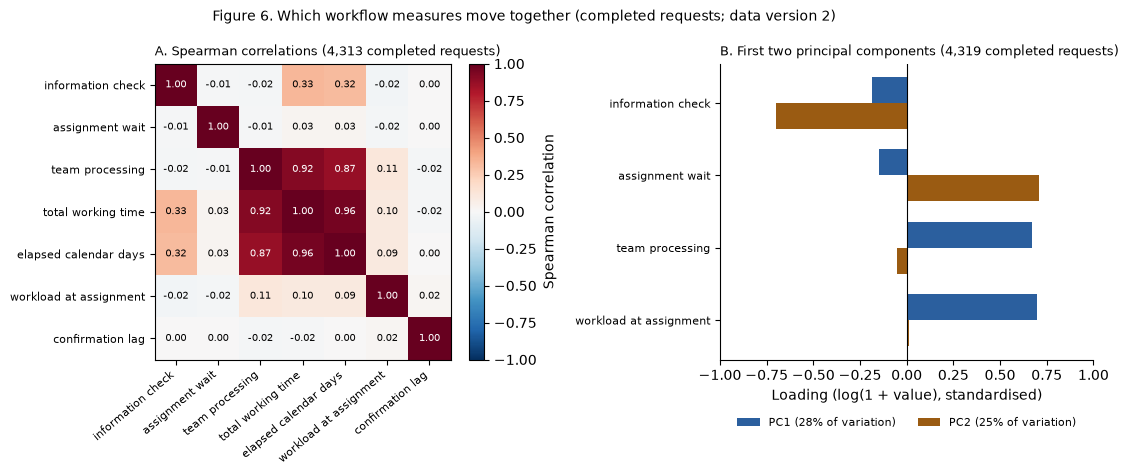

In [5]:
# Figure 6: Spearman correlations (A) and the loadings of the first two principal components (B)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
im = ax1.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax1.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right", fontsize=8)
ax1.set_yticks(range(len(corr)), corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax1.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04, label="Spearman correlation")
ax1.set_title(f"A. Spearman correlations ({len(corr_data):,} completed requests)", fontsize=9, loc="left")
yy = np.arange(len(loadings))
for k, (pc, colour) in enumerate(zip(["PC1", "PC2"], ["#2b5f9e", "#9a5b12"])):
    ax2.barh(yy + (k - 0.5) * 0.36, loadings[pc], 0.36, color=colour,
             label=f"{pc} ({pca_summary.loc[pc, 'explained_variance_%']:.0f}% of variation)")
ax2.axvline(0, color="black", lw=0.8)
ax2.set_yticks(yy, loadings.index, fontsize=8)
ax2.invert_yaxis()
ax2.set_xlim(-1, 1)
ax2.set_xlabel("Loading (log(1 + value), standardised)")
ax2.set_title(f"B. First two principal components ({len(Z):,} completed requests)", fontsize=9, loc="left")
ax2.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
ax2.spines[["top", "right"]].set_visible(False)
fig.suptitle("Figure 6. Which workflow measures move together (completed requests; data version 2)", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "workflow_relationships.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 6 caption.** *What it shows:* panel A gives Spearman rank correlations among seven workflow measures for the 4,313 completed requests with every measure (6 not yet confirmed by the extract are left out). Panel B gives the loadings of the first two principal components of the three stage times and workload at assignment (log(1 + value) of hours and of open tasks, standardised; all 4,319 completed requests), with the share of variation each accounts for. *Why it matters:* the three stage times show little monotonic association with one another (correlations between −0.02 and −0.01), and workload at assignment is only weakly related to team processing (0.11). Team processing and total working time are strongly correlated (0.92), but partly by construction: team processing makes up most of the total, which is the sum of the stages, and elapsed calendar days span the same interval (0.96 with total working time). The confirmation lag is unrelated to the other measures (correlations between −0.02 and 0.02). In the PCA, the four components account for similar shares of the variation (28.0%, 25.3%, 24.6% and 22.1%), close to the 25% each would take if the measures were unrelated, so no single combination stands out and the individual loadings should not be read as distinct patterns. *What it can't establish:* why the measures behave this way, or whether the same weak relationships would hold in a real workflow; rank correlations and components describe association in generated data, and the definitions tie some measures together by arithmetic.

**What section B shows.** Stage durations showed little monotonic association with one another. Workload at assignment had a weak positive association with team-processing time. The workflow measures do not reduce to a few shared patterns in these generated records, which is consistent with examining the stages separately, as notebooks 02 and 03 did; this analysis does not show that one approach is best.

## C. Sensitivity: do the findings hold?

**Sensitivity check 1 — the after-hours intake rule.** H1 counts each request's time from its actual submission in elapsed calendar time (the requester's wait); H3 leaves after-hours submissions out; H4 narrows the after-hours label to weekend and closure-date submissions.

**Sensitivity check 2 — unfinished requests (an inclusion issue).** U1 adds the 45 unfinished requests with their working time so far; U2 adds them as longer than every completed request.

**Secondary checks.** H2 counts closure dates as working days; O1 leaves out the long tail above the fence.

Every scenario is run with the rules fixed at the top of this notebook. For each one the cells below report its population (requests and employees), its overall summaries, stage shares, task-type ordering, the 13 contrasts with their intervals, coverage and weights, and the spring comparison. The written findings of notebooks 02 and 03 are then labelled against these results. One rule not spelled out above, fixed before any scenario result was computed: the overall-median finding counts as unchanged when a scenario's median is within 0.25 working-day equivalents of the reference, the same threshold used for task-type swaps.

In [6]:
# Unfinished requests: stage time accumulated up to the extract (U1), and the single U2 value
u = unfinished.copy()
u["info_check_h"] = [working_hours(s, e if pd.notna(e) else EXTRACT_AT) for s, e in zip(u["submitted_at"], u["info_complete_at"])]
u["assignment_wait_h"] = [0.0 if pd.isna(i) else working_hours(i, a if pd.notna(a) else EXTRACT_AT)
                          for i, a in zip(u["info_complete_at"], u["assigned_at"])]
u["team_processing_h"] = [0.0 if pd.isna(a) else working_hours(a, EXTRACT_AT) for a in u["assigned_at"]]
assert np.allclose(u[STAGES].sum(axis=1), u["days_so_far"] * DAY_HOURS), "Accumulated stage time must add up to time so far"
U2_VALUE = max(completed["processing_days"].max(), u["days_so_far"].max()) + 1
print(f"Unfinished requests: {len(u)} (all submitted {u['submitted_at'].min():%d %b} to {u['submitted_at'].max():%d %b %Y}); "
      f"not yet assigned: {int(u['assigned_at'].isna().sum())}; longest time so far {u['days_so_far'].max():.2f}; "
      f"U2 value {U2_VALUE:.2f} working-day equivalents")

# H2: closure dates counted as working days (Monday-Friday, 08:00-16:30 unchanged)
h2 = completed.copy()
h2_times = durations(h2, closures=set())
h2[STAGES + ["processing_days"]] = h2_times[STAGES + ["processing_days"]].to_numpy()
h2["processing_h"] = h2["processing_days"] * DAY_HOURS

# Each scenario: its requests (rows), the outcome used, and what kind of change it is
U = pd.concat([completed.assign(unfinished=False), u.assign(unfinished=True)], ignore_index=True)
U["processing_h"] = U[STAGES].sum(axis=1)
SCENARIOS = {
    "reference": dict(df=completed, y="processing_days", check="reference", kind="—", units="working-day equivalents"),
    "H1 elapsed calendar time": dict(df=completed, y="elapsed_calendar_days", check="1: after-hours rule", kind="measurement", units="calendar days"),
    "H3 working-hours submissions only": dict(df=completed[~completed["after_hours"]].reset_index(drop=True), y="processing_days",
                                              check="1: after-hours rule", kind="population", units="working-day equivalents"),
    "H4 narrower after-hours label": dict(df=completed.assign(after_hours=completed["after_hours_narrow"]), y="processing_days",
                                          check="1: after-hours rule", kind="classification", units="working-day equivalents"),
    "U1 unfinished, time so far": dict(df=U.assign(outcome=np.where(U["unfinished"], U["days_so_far"], U["processing_days"])), y="outcome",
                                       check="2: unfinished requests", kind="population", units="working-day equivalents"),
    "U2 unfinished, longest": dict(df=U.assign(outcome=np.where(U["unfinished"], U2_VALUE, U["processing_days"])), y="outcome",
                                   check="2: unfinished requests", kind="population", units="working-day equivalents"),
    "H2 closures as working days": dict(df=h2, y="processing_days", check="secondary", kind="calendar", units="working-day equivalents"),
    "O1 without the long tail": dict(df=completed[completed["processing_days"] <= FENCE].reset_index(drop=True), y="processing_days",
                                     check="secondary", kind="population", units="working-day equivalents"),
}
NAMES = list(SCENARIOS)
moved = int((completed["after_hours"] & ~completed["after_hours_narrow"]).sum())
print(f"H4 relabels {moved} completed weekday submissions outside 08:00-16:30 as working-hours submissions "
      f"(after-hours: {int(completed['after_hours'].sum())} -> {int(completed['after_hours_narrow'].sum())})")


def overall(spec):
    df, y = spec["df"], spec["df"][spec["y"]]
    q1, med, q3, p90 = y.quantile([0.25, 0.5, 0.75, 0.9])
    row = {"check": spec["check"], "kind of change": spec["kind"], "units": spec["units"], "requests": len(df),
           "employees": df["employee_id"].nunique(), "median": med, "q1": q1, "q3": q3, "p90": p90}
    if spec["units"] == "working-day equivalents":
        row["above the reference fence"] = int((y > FENCE).sum())
        row["above the reference fence %"] = 100 * (y > FENCE).mean()
    return row


summary_s = pd.DataFrame({n: overall(SCENARIOS[n]) for n in NAMES}).T
for c in ["requests", "employees"]:
    summary_s[c] = summary_s[c].astype(int)
summary_s.insert(0, "data_version", DATA_VERSION)
summary_s.to_csv(OUTPUT_DIR / "sensitivity_summaries.csv")
print("Population and overall summaries by scenario:")
display(summary_s.drop(columns="data_version").round(2))

# Bounds on percentiles of all requests (completed and unfinished): U1 is a lower bound, U2 an upper bound
longest_completed = completed["processing_days"].max()
bounds = pd.DataFrame({q: {"completed only": completed["processing_days"].quantile(p),
                           "lower bound (U1)": SCENARIOS["U1 unfinished, time so far"]["df"]["outcome"].quantile(p),
                           "upper bound (U2)": SCENARIOS["U2 unfinished, longest"]["df"]["outcome"].quantile(p)}
                       for q, p in [("q1", 0.25), ("median", 0.5), ("q3", 0.75), ("p90", 0.9), ("p99", 0.99)]}).T
# The upper bound is valid only where the percentile's position, and the neighbour used for interpolation, fall among completed requests
n_all, n_done = len(U), len(completed)
reaches_unfinished = {q: int(np.ceil(p * (n_all - 1))) >= n_done for q, p in [("q1", 0.25), ("median", 0.5), ("q3", 0.75), ("p90", 0.9), ("p99", 0.99)]}
bounds = bounds.rename(columns={"upper bound (U2)": "U2 scenario value"})
bounds["upper bound status"] = ["unbounded" if reaches_unfinished[q] else "bounded" for q in bounds.index]
bounds["upper bound"] = bounds["U2 scenario value"].where(bounds["upper bound status"] == "bounded")   # empty when unbounded
bounds = bounds[["completed only", "lower bound (U1)", "upper bound", "upper bound status", "U2 scenario value"]]
bounds.to_csv(OUTPUT_DIR / "unfinished_percentile_bounds.csv")
print(f"Percentiles of all {len(U):,} requests: U1 gives a lower bound; the upper bound is finite only where the percentile "
      "falls among completed requests (working-day equivalents):")
display(bounds.round(2))

# Stage shares (working time; U1 is time accumulated up to the extract)
STAGE_SCENARIOS = {"reference": completed, "H2 closures as working days": h2,
                   "H3 working-hours submissions only": SCENARIOS["H3 working-hours submissions only"]["df"],
                   "U1 unfinished, time so far (accumulated to the extract)": U,
                   "O1 without the long tail": SCENARIOS["O1 without the long tail"]["df"]}
stage_s = pd.DataFrame({n: stage_table(df)["share_of_total_%"] for n, df in STAGE_SCENARIOS.items()}).T
stage_s["longest stage"] = stage_s.idxmax(axis=1)
stage_s.to_csv(OUTPUT_DIR / "sensitivity_stage_shares.csv")
print("Share of total working time by stage (%); H1 is in calendar time and H4 changes only a label, so neither is shown:")
display(stage_s.round(1))

# Task-type ordering by median
medians = pd.DataFrame({n: SCENARIOS[n]["df"].groupby("task_type")[SCENARIOS[n]["y"]].median() for n in NAMES}).T[TASK_ORDER]
order = medians.apply(lambda row: " < ".join(t.replace("_", " ") for t in row.sort_values().index), axis=1)
ref_med = medians.loc["reference"]


def swap_kind(name):
    ref_rank, rank = ref_med.rank(), medians.loc[name].rank()
    swapped = [(a, b) for i, a in enumerate(TASK_ORDER) for b in TASK_ORDER[i + 1:]
               if (ref_rank[a] - ref_rank[b]) * (rank[a] - rank[b]) < 0]
    if not swapped:
        return "same order"
    small = all(abs(ref_med[a] - ref_med[b]) < 0.25 for a, b in swapped)
    pairs = "; ".join(f"{a} / {b}" for a, b in swapped)
    return ("small swap: " if small else "order change: ") + pairs


task_order = pd.DataFrame({"order (shortest to longest median)": order, "compared with the reference": [swap_kind(n) for n in NAMES]})
medians.to_csv(OUTPUT_DIR / "sensitivity_task_medians.csv")
task_order.to_csv(OUTPUT_DIR / "sensitivity_task_order.csv")
print("Task types ordered by median (each scenario in its own units):")
with pd.option_context("display.max_colwidth", None):
    display(task_order)

# Spring 2025 vs spring 2026 (submissions in March-May), median difference
def spring_gap(spec):
    df, y = spec["df"], spec["df"][spec["y"]]
    s = df["submitted_at"]
    spring = s.dt.month.isin([3, 4, 5])
    m25, m26 = y[spring & (s.dt.year == 2025)].median(), y[spring & (s.dt.year == 2026)].median()
    return pd.Series({"spring 2025 median": m25, "spring 2026 median": m26, "2026 - 2025": m26 - m25,
                      "requests 2025": int((spring & (s.dt.year == 2025)).sum()), "requests 2026": int((spring & (s.dt.year == 2026)).sum())})


spring_s = pd.DataFrame({n: spring_gap(SCENARIOS[n]) for n in NAMES}).T
spring_s[["requests 2025", "requests 2026"]] = spring_s[["requests 2025", "requests 2026"]].astype(int)
spring_s.to_csv(OUTPUT_DIR / "sensitivity_spring.csv")
print("Spring submissions (March-May), median by year:")
display(spring_s.round(2))

Unfinished requests: 45 (all submitted 10 Sep to 29 Sep 2026); not yet assigned: 6; longest time so far 13.06; U2 value 41.66 working-day equivalents
H4 relabels 470 completed weekday submissions outside 08:00-16:30 as working-hours submissions (after-hours: 650 -> 180)
Population and overall summaries by scenario:


,check,kind of change,units,requests,employees,median,q1,q3,p90,above the reference fence,above the reference fence %
reference,reference,—,working-day equivalents,4319,1065,4.658824,3.363725,6.690196,9.288235,154,3.56564
H1 elapsed calendar time,1: after-hours rule,measurement,calendar days,4319,1065,6.928472,4.984722,9.855556,13.799444,NaN,NaN
H3 working-hours submissions only,1: after-hours rule,population,working-day equivalents,3669,1062,4.613725,3.309804,6.629412,9.258824,125,3.406923
H4 narrower after-hours label,1: after-hours rule,classification,working-day equivalents,4319,1065,4.658824,3.363725,6.690196,9.288235,154,3.56564
"U1 unfinished, time so far",2: unfinished requests,population,working-day equivalents,4364,1073,4.638235,3.328922,6.678431,9.27,156,3.574702
"U2 unfinished, longest",2: unfinished requests,population,working-day equivalents,4364,1073,4.696078,3.386275,6.778922,9.51,199,4.560037
H2 closures as working days,secondary,calendar,working-day equivalents,4319,1065,4.84902,3.460784,6.895098,9.636078,195,4.514934
O1 without the long tail,secondary,population,working-day equivalents,4165,1065,4.529412,3.307843,6.380392,8.520784,0,0.0


Percentiles of all 4,364 requests: U1 gives a lower bound; the upper bound is finite only where the percentile falls among completed requests (working-day equivalents):


,completed only,lower bound (U1),upper bound,upper bound status,U2 scenario value
q1,3.36,3.33,3.39,bounded,3.39
median,4.66,4.64,4.70,bounded,4.70
q3,6.69,6.68,6.78,bounded,6.78
p90,9.29,9.27,9.51,bounded,9.51
p99,26.79,26.59,NaN,unbounded,41.66


Share of total working time by stage (%); H1 is in calendar time and H4 changes only a label, so neither is shown:


,information check,assignment wait,team processing,longest stage
reference,6.5,4.7,88.8,team processing
H2 closures as working days,6.5,4.6,88.8,team processing
H3 working-hours submissions only,6.5,4.7,88.8,team processing
"U1 unfinished, time so far (accumulated to the extract)",6.5,4.7,88.8,team processing
O1 without the long tail,6.6,5.2,88.1,team processing


Task types ordered by median (each scenario in its own units):


,order (shortest to longest median),compared with the reference
reference,orientation scheduling < system access < workplace access < payroll setup < equipment setup,same order
H1 elapsed calendar time,orientation scheduling < system access < workplace access < payroll setup < equipment setup,same order
H3 working-hours submissions only,orientation scheduling < system access < workplace access < payroll setup < equipment setup,same order
H4 narrower after-hours label,orientation scheduling < system access < workplace access < payroll setup < equipment setup,same order
"U1 unfinished, time so far",orientation scheduling < system access < workplace access < payroll setup < equipment setup,same order
"U2 unfinished, longest",orientation scheduling < system access < workplace access < payroll setup < equipment setup,same order
H2 closures as working days,orientation scheduling < system access < workplace access < payroll setup < equipment setup,same order
O1 without the long tail,orientation scheduling < system access < workplace access < payroll setup < equipment setup,same order


Spring submissions (March-May), median by year:


,spring 2025 median,spring 2026 median,2026 - 2025,requests 2025,requests 2026
reference,4.70,4.49,-0.21,860,895
H1 elapsed calendar time,6.94,6.80,-0.15,860,895
H3 working-hours submissions only,4.64,4.49,-0.15,723,766
H4 narrower after-hours label,4.70,4.49,-0.21,860,895
"U1 unfinished, time so far",4.70,4.49,-0.21,860,895
"U2 unfinished, longest",4.70,4.49,-0.21,860,895
H2 closures as working days,4.85,4.66,-0.20,860,895
O1 without the long tail,4.62,4.42,-0.19,831,860


In [7]:
# The 13 contrasts in every scenario (2,000 employee resamples each, seed 2026)
tables, weight_rows = {}, []
for n in NAMES:
    spec = SCENARIOS[n]
    t, plans = contrast_table(spec["df"], spec["df"][spec["y"]].to_numpy(dtype=float))
    tables[n] = t
    for p in plans:
        for k, w in (p.get("stratum_weights") or {}).items():
            weight_rows.append({"scenario": n, "contrast": p["label"], "stratum": k, "weight": w, "coverage_%": p["coverage_%"]})
contrasts_s = pd.concat({n: t.set_index("contrast") for n, t in tables.items()}, names=["scenario", "contrast"])
assert contrasts_s.loc["reference"][["estimate_days", "ci_low", "ci_high"]].round(9).equals(
    reference.set_index("contrast")[["estimate_days", "ci_low", "ci_high"]].round(9)), "The reference scenario must reproduce notebook 03"
contrasts_s.insert(0, "data_version", DATA_VERSION)
contrasts_s.to_csv(OUTPUT_DIR / "sensitivity_contrasts.csv")
pd.DataFrame(weight_rows).to_csv(OUTPUT_DIR / "sensitivity_stratum_weights.csv", index=False)
not_estimable = contrasts_s[~contrasts_s["applicable"]]
print(f"Contrasts not applicable or not estimable: {len(not_estimable)}")
if len(not_estimable):
    display(not_estimable[["reason"]])

# Compare each scenario with the reference: direction, size and the interval's relation to zero
CONTRAST_LABELS = reference["contrast"].tolist()
ref_c = contrasts_s.loc["reference"]
sign = lambda v: np.sign(v)
def zero_rel(lo, hi):
    if pd.isna(lo) or pd.isna(hi):
        return "interval unavailable"                                # missing evidence is never read as "includes zero"
    return "excludes zero" if (lo > 0 or hi < 0) else "includes zero"


unavailable = lambda row: "not estimable" if str(row["reason"]).startswith("no stratum") else "not applicable"
rows = []
for n in NAMES[1:]:
    for c in CONTRAST_LABELS:
        s, ref = contrasts_s.loc[(n, c)], ref_c.loc[c]
        if not s["applicable"]:
            status, direction, interval = unavailable(s), "", ""
        elif s["interval_withheld"]:
            status, direction, interval = "interval unavailable", "", "interval unavailable"
        else:
            direction = "same direction" if sign(s["estimate_days"]) == sign(ref["estimate_days"]) else "direction changes"
            interval = ("same relation to zero" if zero_rel(s["ci_low"], s["ci_high"]) == zero_rel(ref["ci_low"], ref["ci_high"])
                        else f"interval now {zero_rel(s['ci_low'], s['ci_high'])}")
            status = "unchanged" if direction == "same direction" and interval == "same relation to zero" else "changed"
        rows.append({"scenario": n, "contrast": c, "status": status, "direction": direction, "interval vs zero": interval,
                     "change in estimate": (s["estimate_days"] - ref["estimate_days"]) if SCENARIOS[n]["units"] == "working-day equivalents"
                     and s["applicable"] else np.nan})
changes = pd.DataFrame(rows)
changes.to_csv(OUTPUT_DIR / "sensitivity_contrast_changes.csv", index=False)
print("Contrasts whose direction or interval relation to zero changes:")
display(changes[changes["status"] == "changed"].set_index(["scenario", "contrast"]).round(2))
print("Largest change in a contrast estimate, by scenario (working-day equivalents; H1 is in calendar days and not compared):")
display(changes.groupby("scenario")["change in estimate"].apply(lambda v: v.abs().max()).reindex(NAMES[1:]).round(2).to_frame())

Contrasts not applicable or not estimable: 2


reason
scenario                          contrast                                                                                      
H3 working-hours submissions only after-hours - working hours                         a compared group is empty in this scenario
                                  after-hours - working hours, within information...  a compared group is empty in this scenario

Contrasts whose direction or interval relation to zero changes:


status  \
scenario                          contrast                                                      
H1 elapsed calendar time          workplace_access - payroll_setup                    changed   
                                  high - low workload, within task type               changed   
                                  after-hours - working hours                         changed   
                                  after-hours - working hours, within information...  changed   
                                  email - web form                                    changed   
H3 working-hours submissions only workplace_access - payroll_setup                    changed   
                                  email - web form                                    changed   
H4 narrower after-hours label     after-hours - working hours                         changed   
                                  after-hours - working hours, within information...  changed   
U2 unfinished, longest            workplace_access - payroll_setup                    changed   
                                  email - web form                                    changed   
H2 closures as working days       workplace_access - payroll_setup                    changed   
                                  after-hours - working hours                         changed   
                                  email - web form                                    changed   

                                                                                              direction  \
scenario                          contrast                                                                
H1 elapsed calendar time          workplace_access - payroll_setup                       same direction   
                                  high - low workload, within task type               direction changes   
                                  after-hours - working hours                            same direction   
                                  after-hours - working hours, within information...     same direction   
                                  email - web form                                    direction changes   
H3 working-hours submissions only workplace_access - payroll_setup                       same direction   
                                  email - web form                                    direction changes   
H4 narrower after-hours label     after-hours - working hours                            same direction   
                                  after-hours - working hours, within information...     same direction   
U2 unfinished, longest            workplace_access - payroll_setup                       same direction   
                                  email - web form                                    direction changes   
H2 closures as working days       workplace_access - payroll_setup                       same direction   
                                  after-hours - working hours                            same direction   
                                  email - web form                                    direction changes   

                                                                                                interval vs zero  \
scenario                          contrast                                                                         
H1 elapsed calendar time          workplace_access - payroll_setup                    interval now excludes zero   
                                  high - low workload, within task type                    same relation to zero   
                                  after-hours - working hours                         interval now includes zero   
                                  after-hours - working hours, within information...  interval now includes zero   
                                  email - web form                                         same relation to zero   
H3 workin

Largest change in a contrast estimate, by scenario (working-day equivalents; H1 is in calendar days and not compared):


,change in estimate
scenario,
H1 elapsed calendar time,NaN
H3 working-hours submissions only,0.10
H4 narrower after-hours label,0.03
"U1 unfinished, time so far",0.04
"U2 unfinished, longest",0.07
H2 closures as working days,0.16
O1 without the long tail,0.22


**Labelling the written findings.** Each finding of notebooks 02 and 03 is compared with every scenario. A contrast whose reference interval excludes zero is a claim about direction: it stays unchanged only if the scenario's estimate has the same sign and its interval still excludes zero. A contrast whose reference interval includes zero is the finding "no clear difference": it stays unchanged as long as the scenario's interval also includes zero. This second rule was made explicit after the scenario results showed some near-zero estimates (email against web form, workload within task type) changing sign while their intervals still included zero; consistent with the rule fixed at the start of the notebook (only changes that affect a written finding change its label), such sign changes are reported in the change table above but do not change the "no clear difference" finding. Under H1 only direction and the interval's relation to zero are compared, because its sizes are in calendar days.

In [8]:
# Label each written finding of notebooks 02 and 03 across the scenarios
def contrast_finding(c):
    ref = ref_c.loc[c]
    claims_direction = ref["ci_low"] > 0 or ref["ci_high"] < 0
    cells = {}
    for n in NAMES[1:]:
        s = contrasts_s.loc[(n, c)]
        if not s["applicable"]:
            cells[n] = unavailable(s)
        elif s["interval_withheld"]:
            cells[n] = "interval unavailable"
        elif claims_direction:
            same = sign(s["estimate_days"]) == sign(ref["estimate_days"]) and (s["ci_low"] > 0 or s["ci_high"] < 0)
            cells[n] = "unchanged" if same else ("interval includes zero" if sign(s["estimate_days"]) == sign(ref["estimate_days"])
                                                 else "direction changes")
        else:                                                         # the finding is "no clear difference"
            cells[n] = "unchanged" if not (s["ci_low"] > 0 or s["ci_high"] < 0) else "interval excludes zero"
    statement = (f"{'longer' if ref['estimate_days'] > 0 else 'shorter'} ({ref['estimate_days']:+.2f}; interval excludes zero)"
                 if claims_direction else f"no clear difference ({ref['estimate_days']:+.2f}; interval includes zero)")
    return statement, cells


findings = []
med_cells = {n: ("not comparable" if SCENARIOS[n]["units"] != "working-day equivalents" else
                 ("unchanged" if abs(summary_s.loc[n, "median"] - summary_s.loc["reference", "median"]) < 0.25 else "median moves 0.25 or more"))
             for n in NAMES[1:]}
findings.append(("Median processing time about 4.7 working-day equivalents", "notebook 02", med_cells))
stage_cells = {n: ("unchanged" if stage_s.loc[k, "longest stage"] == "team processing" else "longest stage changes")
               for n, k in [("H2 closures as working days", "H2 closures as working days"),
                            ("H3 working-hours submissions only", "H3 working-hours submissions only"),
                            ("U1 unfinished, time so far", "U1 unfinished, time so far (accumulated to the extract)"),
                            ("O1 without the long tail", "O1 without the long tail")]}
stage_cells.update({"H1 elapsed calendar time": "not comparable", "H4 narrower after-hours label": "unchanged",
                    "U2 unfinished, longest": "not applicable"})
findings.append(("Team processing is the longest stage", "notebook 02", stage_cells))
findings.append(("Task types from shortest to longest median: orientation, system access, workplace access, payroll, equipment",
                 "notebook 02", {n: ("unchanged" if task_order.loc[n, "compared with the reference"] == "same order" else
                                     task_order.loc[n, "compared with the reference"]) for n in NAMES[1:]}))
for c in CONTRAST_LABELS:
    statement, cells = contrast_finding(c)
    findings.append((f"{c.replace('_', ' ')}: {statement}", "notebook 03", cells))
findings.append(("Spring 2026 submissions took slightly less time than spring 2025 (descriptive, no interval)", "notebook 03",
                 {n: ("unchanged" if spring_s.loc[n, "2026 - 2025"] < 0 else "direction changes") for n in NAMES[1:]}))

finding_table = pd.DataFrame([{"finding": f, "source": src, **cells} for f, src, cells in findings]).set_index("finding")


NOT_ASSESSABLE = ("not estimable", "interval unavailable")


def label(row):
    cells = row[NAMES[1:]]
    changed = [n for n in NAMES[1:] if cells[n] not in ("unchanged", "not applicable", "not comparable") + NOT_ASSESSABLE]
    missing = [n for n in NAMES[1:] if cells[n] in NOT_ASSESSABLE]
    if changed:
        text = "depends on scenario: " + "; ".join(n.split(" ")[0] for n in changed)
    elif all(cells[n] == "not applicable" for n in NAMES[1:]):
        text = "not applicable"
    else:
        text = "unchanged where assessable" if missing else "stable"
    return text + (" (not assessable in: " + "; ".join(n.split(" ")[0] for n in missing) + ")" if missing else "")


finding_table.insert(1, "label", finding_table.apply(label, axis=1))
finding_table.to_csv(OUTPUT_DIR / "sensitivity_findings.csv")
print(f"Findings: {int((finding_table['label'] == 'stable').sum())} stable, "
      f"{int(finding_table['label'].str.startswith('depends').sum())} depend on a scenario")
with pd.option_context("display.max_colwidth", 90):
    display(finding_table[["source", "label"]])

Findings: 14 stable, 3 depend on a scenario


,source,label
finding,,
Median processing time about 4.7 working-day equivalents,notebook 02,stable
Team processing is the longest stage,notebook 02,stable
"Task types from shortest to longest median: orientation, system access, workplace access, payroll, equipment",notebook 02,stable
equipment setup - payroll setup: longer (+0.66; interval excludes zero),notebook 03,stable
system access - payroll setup: shorter (-0.81; interval excludes zero),notebook 03,stable
workplace access - payroll setup: no clear difference (-0.19; interval includes zero),notebook 03,depends on scenario: H1; H3; U2; H2
orientation scheduling - payroll setup: shorter (-1.17; interval excludes zero),notebook 03,stable
information issue - none: longer (+2.80; interval excludes zero),notebook 03,stable
high - low workload: longer (+0.59; interval excludes zero),notebook 03,stable


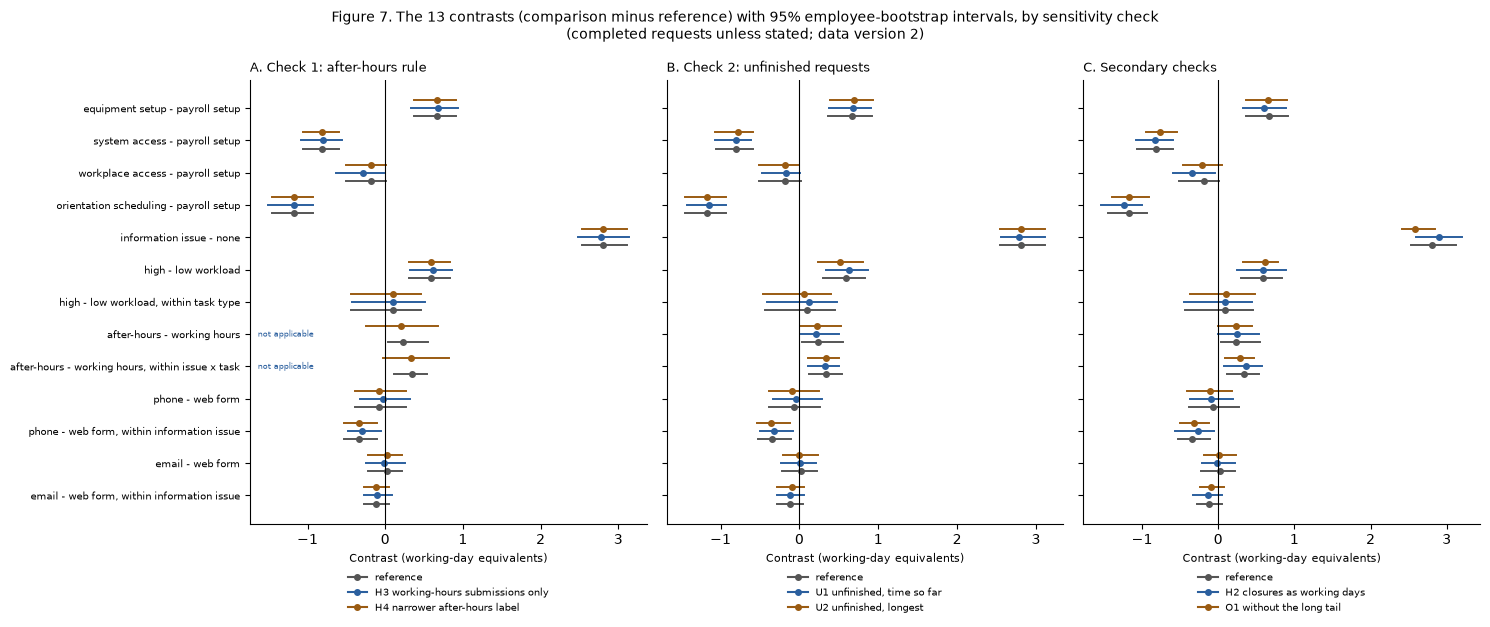

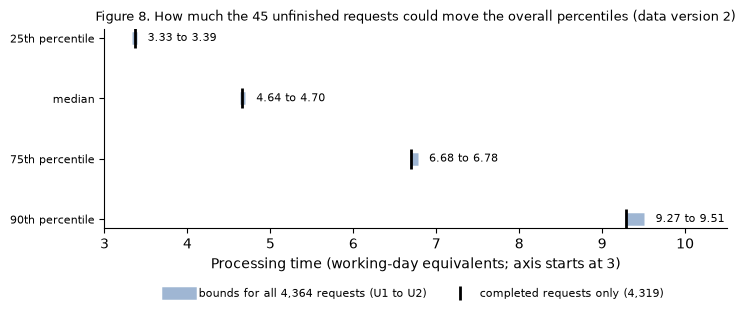

In [9]:
# Figure 7: the 13 contrasts in each sensitivity check, one panel per check (H1 is in calendar days and is in the table only)
PANELS = [("A. Check 1: after-hours rule", ["reference", "H3 working-hours submissions only", "H4 narrower after-hours label"]),
          ("B. Check 2: unfinished requests", ["reference", "U1 unfinished, time so far", "U2 unfinished, longest"]),
          ("C. Secondary checks", ["reference", "H2 closures as working days", "O1 without the long tail"])]
COL = {"reference": "#555555", "H3 working-hours submissions only": "#2b5f9e", "H4 narrower after-hours label": "#9a5b12",
       "U1 unfinished, time so far": "#2b5f9e", "U2 unfinished, longest": "#9a5b12",
       "H2 closures as working days": "#2b5f9e", "O1 without the long tail": "#9a5b12"}
fig, axes = plt.subplots(1, 3, figsize=(15, 6.4), sharey=True)
ypos = np.arange(len(CONTRAST_LABELS))[::-1]
for ax, (title, scen) in zip(axes, PANELS):
    for k, n in enumerate(scen):
        off = (k - 1) * 0.25
        t = contrasts_s.loc[n].reindex(CONTRAST_LABELS)
        for y0, (_, row) in zip(ypos, t.iterrows()):
            if not row["applicable"]:
                ax.text(0.02, y0 + off, "not applicable", fontsize=6, color=COL[n], va="center", transform=ax.get_yaxis_transform())
                continue
            ax.plot([row["ci_low"], row["ci_high"]], [y0 + off] * 2, color=COL[n], lw=1.4)
            ax.plot(row["estimate_days"], y0 + off, "o", color=COL[n], ms=4)
        ax.plot([], [], "o-", color=COL[n], label=n, ms=4)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(title, fontsize=9, loc="left")
    ax.set_xlabel("Contrast (working-day equivalents)", fontsize=8)
    ax.legend(fontsize=7, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=1)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(ypos, [c.replace("_", " ").replace(", within information issue x task type", ", within issue x task")
                          for c in CONTRAST_LABELS], fontsize=7.5)
fig.suptitle("Figure 7. The 13 contrasts (comparison minus reference) with 95% employee-bootstrap intervals, by sensitivity check\n"
             "(completed requests unless stated; data version 2)", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "sensitivity_contrasts.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 8: bounds on percentiles of all requests (completed and unfinished)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
qs = ["q1", "median", "q3", "p90"]
for i, q in enumerate(qs):
    assert bounds.loc[q, "upper bound status"] == "bounded", "Figure 8 shows only bounded percentiles"
    lo, hi, mid = bounds.loc[q, "lower bound (U1)"], bounds.loc[q, "upper bound"], bounds.loc[q, "completed only"]
    ax.plot([lo, hi], [i, i], color="#2b5f9e", lw=9, alpha=0.45, solid_capstyle="butt")
    ax.plot(mid, i, "|", color="black", ms=14, mew=2)
    ax.annotate(f"{lo:.2f} to {hi:.2f}", (hi, i), xytext=(8, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_yticks(range(len(qs)), ["25th percentile", "median", "75th percentile", "90th percentile"], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Processing time (working-day equivalents; axis starts at 3)")
ax.set_xlim(3, 10.5)
ax.plot([], [], color="#2b5f9e", lw=9, alpha=0.45, label=f"bounds for all {len(U):,} requests (U1 to U2)")
ax.plot([], [], "|", color="black", ms=10, mew=2, label=f"completed requests only ({len(completed):,})")
ax.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Figure 8. How much the 45 unfinished requests could move the overall percentiles (data version 2)", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "unfinished_bounds.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 7 caption.** *What it shows:* each of notebook 03's 13 contrasts (comparison minus reference group, working-day equivalents) with its 95% employee-bootstrap interval, in the reference analysis (grey) and in the scenarios of each sensitivity check: A, the after-hours rule (H3, H4); B, unfinished requests (U1, U2); C, the secondary checks (H2, O1). H1 is in calendar days and appears only in the tables. *Why it matters:* most contrasts barely move. The clear exceptions are the two after-hours contrasts under the narrower label (H4): their estimates stay similar (+0.20 and +0.33, against +0.23 and +0.34) but, with 180 rather than 650 after-hours requests, their intervals widen to include zero. The workplace-access contrast sits close to zero in the reference (−0.19, interval −0.51 to +0.02) and excludes zero in several scenarios. *What it can't establish:* why after-hours submissions might take longer, or whether these differences would appear in a real HR operation; the intervals reflect resampling of employees in generated data, not every source of uncertainty.

**Figure 8 caption.** *What it shows:* for the 25th, 50th, 75th and 90th percentiles of all 4,364 requests (completed and unfinished), the range between the lower bound (U1: unfinished requests at their working time so far) and the upper bound (U2: unfinished requests longer than every completed one), with the completed-only value marked. The axis starts at 3 working-day equivalents. *Why it matters:* whatever the 45 unfinished requests eventually take, the overall median lies between 4.64 and 4.70 and the 90th percentile between 9.27 and 9.51, so leaving them out of the completed-request summaries hardly changes those summaries. *What it can't establish:* the eventual times of the unfinished requests, or an upper bound for the most extreme percentiles: the 99th percentile is at least 26.59, but it falls among the unfinished requests and has no upper bound. The U2 scenario's finite value is an assumption, not a bound.

**What section C shows.**

- **Sensitivity check 1, the after-hours intake rule.** Leaving after-hours submissions out (H3: 3,669 requests from 1,062 employees) moves the median from 4.66 to 4.61 and leaves the stage shares and task order unchanged; the after-hours contrasts do not apply. Narrowing the label to weekend and closure-date submissions (H4: 470 weekday evening, night and early-morning submissions relabelled, leaving 180 after-hours requests) leaves the after-hours estimates similar in size but makes both intervals include zero (raw +0.20, −0.25 to +0.68; within information issue × task type +0.33, −0.03 to +0.82). In elapsed calendar time (H1), the after-hours intervals also include zero. The estimated after-hours difference remained positive, but its interval included zero under the narrower definition and calendar-time measure. Support for a directional finding therefore depends on the definition and measurement choice.
- **Sensitivity check 2, unfinished requests.** Adding the 45 unfinished requests (U1, U2: 4,364 requests from 1,073 employees) bounds the overall median between 4.64 and 4.70 and the 90th percentile between 9.27 and 9.51, and, under the U1 and finite U2 assumptions tested, changes every contrast estimate by less than 0.08 working-day equivalents. The only changed finding is the borderline workplace-access contrast, whose interval excludes zero under U2. **The conclusions do not change**, apart from that borderline case.
- **Secondary checks.** Counting closures as working days (H2) raises the median to 4.85 and moves the workplace-access contrast to −0.35 (interval excludes zero); the raw after-hours interval just includes zero (−0.002 to +0.54) while the within-stratum one still excludes it. Leaving out the long tail (O1) lowers the median to 4.53 and the information-issue contrast from +2.80 to +2.58, without changing any finding.
- **Overall.** Under the labelling rules above (including the "no clear difference" rule made explicit after the results were seen), 14 of the 17 written findings are unchanged in every applicable scenario: the median processing time, team processing as the longest stage, the task-type order, the equipment, system-access and orientation contrasts against payroll, the information-issue, workload and channel contrasts, and the spring comparison. Three depend on a scenario: the two after-hours contrasts (on the after-hours definition and the measure of time; their estimates stay positive) and the borderline workplace-access contrast (on the measure of time, the calendar, the population and the treatment of unfinished requests; its estimate is negative in every scenario). No finding was left unassessed: no interval was withheld and no contrast was unestimable.

**What this means for the recommendations.** The recommended action changes only where a finding depends on a scenario. Recommendations about information issues, task types and the long tail can rest on these results. Any recommendation about after-hours submissions should be conditional on how after-hours is defined and stated as an association, and the workplace-access difference should be presented as small and uncertain. These are associations in generated data, not causes, and they do not show how a real HR operation would behave.

## D. Checks

In [10]:
count_files = {"sensitivity_summaries.csv": ["requests", "employees"], "sensitivity_spring.csv": ["requests 2025", "requests 2026"],
               "sensitivity_contrasts.csv": ["comparison_requests", "reference_requests", "valid_resamples"],
               "outlier_makeup_counts.csv": GROUP_ORDER + ["all completed", "without the tail (O1)"],
               "outlier_stage_summary.csv": ["requests"], "robust_summaries.csv": ["requests"]}
ALLOWED_CELLS = {"unchanged", "not applicable", "not comparable", "not estimable", "interval unavailable", "interval includes zero",
                 "interval excludes zero", "direction changes", "median moves 0.25 or more", "longest stage changes"}
scen = {n: SCENARIOS[n]["df"] for n in NAMES}
pct_positions = {"q1": 0.25, "median": 0.5, "q3": 0.75, "p90": 0.9, "p99": 0.99}
ids = lambda df: set(df["request_id"])
done_ids, unfinished_ids = ids(completed), ids(u)

# Percentile bounds recomputed independently: lower from U1's values; upper with every unfinished request at infinity
u1_values = scen["U1 unfinished, time so far"]["outcome"].to_numpy(dtype=float)
inf_values = np.concatenate([completed["processing_days"].to_numpy(), np.full(len(u), np.inf)])
with np.errstate(invalid="ignore"):
    upper_check = {q: np.quantile(inf_values, p) for q, p in pct_positions.items()}
bounds_ok = all(
    np.isclose(bounds.loc[q, "lower bound (U1)"], np.quantile(u1_values, p))
    and ((not np.isfinite(upper_check[q])) == (bounds.loc[q, "upper bound status"] == "unbounded"))
    and (not np.isfinite(upper_check[q]) or (np.isclose(bounds.loc[q, "upper bound"], upper_check[q])
                                              and bounds.loc[q, "lower bound (U1)"] <= bounds.loc[q, "upper bound"]))
    for q, p in pct_positions.items())

# Each contrast result has the status, reason and missing-value pattern that fits it
def result_ok(row):
    finite = np.isfinite(row[["estimate_days", "ci_low", "ci_high"]].to_numpy(dtype=float))
    if not row["applicable"]:
        return row["reason"] != "" and row["interval_withheld"] and not finite.any()
    if row["interval_withheld"]:
        return row["reason"] == "" and finite[0] and not finite[1:].any()
    return row["reason"] == "" and finite.all() and row["ci_low"] <= row["ci_high"]


unavailable_results = int((~contrasts_s["applicable"] | contrasts_s["interval_withheld"]).sum())

checks = pd.Series({
    "Cleaned file matches its cleaning record (fingerprint)":
        sha(SD / "cleaning/output/requests_cleaned.csv") == cleaning_info["output_sha256"],
    "Generator unchanged since notebook 02 saved the working calendar":
        sha(SD / "requests/generate_requests.py") == calendar["generator_sha256"],
    "Working-time function passes every hand-made test, including closures counted as working days (H2)":
        bool(np.isclose(tests["calculated_hours"], tests["expected_hours"]).all()),
    "Only submissions occur outside working hours (the after-hours design assumes this)":
        all(v == 0 for c, v in after_hours_events.items() if c != "submitted_at"),
    "Reference reproduces notebook 02 (durations, summaries, stages) and notebook 03 (13 contrasts and intervals)":
        bool(REPRO_02 and REPRO_03),
    "An unsupported weighted contrast is reported as not estimable, not as 0 (self-test)":
        not _toy_plan["applicable"] and _toy_plan["reason"].startswith("no stratum"),
    "Length groups cover every completed request once; the long tail matches notebook 02":
        int(completed["length_group"].value_counts().sum()) == len(completed)
        and int((completed["length_group"] == GROUP_ORDER[0]).sum()) == int(ref_summary.loc["working-day equivalents", "unusually_long"]),
    "Stage differences add up to the difference in mean total time (long tail minus middle group)":
        bool(np.isclose(excess.loc[list(STAGE_NAMES.values()), "difference"].sum(), excess.loc["total", "difference"])),
    "PCA uses complete, non-negative inputs and its components account for all the variation":
        bool(np.isfinite(X).all() and np.isclose(pca_summary["explained_variance_%"].sum(), 100)),
    "Each scenario contains exactly its intended requests (by request ID), and H4 relabels request by request":
        all(scen[n]["request_id"].is_unique for n in NAMES)
        and all(ids(scen[n]) == done_ids for n in ["reference", "H1 elapsed calendar time", "H4 narrower after-hours label",
                                                   "H2 closures as working days"])
        and ids(scen["H3 working-hours submissions only"]) == ids(completed[~completed["after_hours"]])
        and ids(scen["O1 without the long tail"]) == ids(completed[completed["processing_days"] <= FENCE])
        and all(ids(scen[n]) == done_ids | unfinished_ids and not (done_ids & unfinished_ids)
                for n in ["U1 unfinished, time so far", "U2 unfinished, longest"])
        and scen["H4 narrower after-hours label"].set_index("request_id")["after_hours"]
            .equals(completed.set_index("request_id")["after_hours_narrow"]),
    "Unfinished stage time adds up to time so far; the U2 value exceeds every completed duration and every time so far":
        bool(np.allclose(u[STAGES].sum(axis=1), u["days_so_far"] * DAY_HOURS))
        and U2_VALUE > completed["processing_days"].max() and U2_VALUE > u["days_so_far"].max(),
    "Percentile bounds match an independent recalculation; lower <= upper wherever the upper bound is finite":
        bool(bounds_ok) and bounds.loc[bounds["upper bound status"] == "unbounded", "upper bound"].isna().all(),
    "Every scenario reports all 13 contrasts":
        all(len(t) == 13 and t["contrast"].tolist() == CONTRAST_LABELS for t in tables.values()),
    "Each contrast result has the status, reason and missing values that fit it (available, withheld or not applicable/estimable)":
        bool(contrasts_s.apply(result_ok, axis=1).all()),
    "H3's after-hours contrasts are not applicable because the after-hours group is empty":
        all(not contrasts_s.loc[("H3 working-hours submissions only", c), "applicable"]
            and contrasts_s.loc[("H3 working-hours submissions only", c), "reason"] == "a compared group is empty in this scenario"
            for c in CONTRAST_LABELS if c.startswith("after-hours")),
    "Every written finding has a label and only allowed statuses":
        finding_table["label"].notna().all() and finding_table[NAMES[1:]].isin(ALLOWED_CELLS).all().all(),
    "Count columns are written as whole numbers (presentation check)":
        all(read(OUTPUT_DIR / f)[cols].apply(lambda c: c.str.fullmatch(r"\d+", na=False)).all().all() for f, cols in count_files.items()),
}, name="passed")
checks.index.name = "check"
checks.to_csv(OUTPUT_DIR / "checks_04.csv")
with pd.option_context("display.max_colwidth", None):
    display(checks.to_frame())
print(f"Contrast results without an estimate or interval: {unavailable_results} of {len(contrasts_s)} "
      f"(not applicable or not estimable: {int((~contrasts_s['applicable']).sum())}; interval withheld: "
      f"{int((contrasts_s['applicable'] & contrasts_s['interval_withheld']).sum())})")
assert checks.all(), "A check failed"

,passed
check,
Cleaned file matches its cleaning record (fingerprint),True
Generator unchanged since notebook 02 saved the working calendar,True
"Working-time function passes every hand-made test, including closures counted as working days (H2)",True
Only submissions occur outside working hours (the after-hours design assumes this),True
"Reference reproduces notebook 02 (durations, summaries, stages) and notebook 03 (13 contrasts and intervals)",True
"An unsupported weighted contrast is reported as not estimable, not as 0 (self-test)",True
Length groups cover every completed request once; the long tail matches notebook 02,True
Stage differences add up to the difference in mean total time (long tail minus middle group),True
"PCA uses complete, non-negative inputs and its components account for all the variation",True


Contrast results without an estimate or interval: 2 of 104 (not applicable or not estimable: 2; interval withheld: 0)


## Summary

**Question:** Do the findings of notebooks 02 and 03 hold when reasonable measurement and population choices change, in particular how after-hours submissions are handled and whether requests unfinished at the extract are included? Which requests are unusually long, and which workflow measures move together?

**Data version:** 2. Official cleaned requests (cleaning version 1.1), notebook 02's working calendar (Monday–Friday, 08:00–16:30, excluding simulated closure dates) and extract time (29 Sep 2026, 17:00). The unit is a request; the reference population is the 4,319 completed requests from 1,065 employees, and the 45 unfinished requests enter only in scenarios U1 and U2. The answer key is not used.

**Method:** The reference analysis (notebooks 02 and 03) was rebuilt and shown to reproduce their saved outputs before anything else was computed. Unusually long requests use notebook 02's fixed Tukey fence; correlations are Spearman rank correlations; the PCA uses log(1 + value) of stage hours and workload counts, standardised. The sensitivity analysis applies seven alternatives fixed in advance, each recording what it changes (measurement, calendar, population or classification), and reruns notebook 03's 13 contrasts with 2,000 employee resamples in each. Findings were labelled against rules set before the scenario results, with one rule (for "no clear difference" findings) made explicit afterwards and disclosed.

**Key findings:**

1. **The long tail is mostly longer team processing.** The 154 requests above the fence (3.6%) had information issues more often than the middle group (33.1% against 12.9%). Their mean processing time was 15.76 working-day equivalents longer, and 95.2% of that difference was in team processing. Leaving them out changes the population's make-up by at most 0.7 percentage points and the median from 4.66 to 4.53.
2. **The workflow measures do not reduce to a few shared patterns.** Stage durations showed little monotonic association with one another (correlations −0.02 to −0.01); workload at assignment had a weak positive association with team processing (0.11). The four principal components account for similar shares of the variation (22–28%).
3. **Sensitivity check 1, the after-hours intake rule.** Leaving after-hours submissions out (3,669 requests) moves the median to 4.61 and changes no other finding except the borderline workplace-access contrast. Under the narrower after-hours label (180 instead of 650 after-hours requests) and in elapsed calendar time, the estimated after-hours difference remained positive, but its interval included zero. Support for a directional after-hours finding therefore depends on the definition and measurement choice.
4. **Sensitivity check 2, unfinished requests.** Whatever the 45 unfinished requests eventually take, the overall median lies between 4.64 and 4.70 and the 90th percentile between 9.27 and 9.51; the 99th percentile is at least 26.59 but has no upper bound. Under the U1 and finite U2 assumptions tested, every contrast estimate changed by less than 0.08 working-day equivalents; only the borderline workplace-access contrast changed its relation to zero.
5. **Most findings are robust.** Under the stated labelling rules, 14 of 17 written findings are unchanged in every applicable scenario, including the median, team processing as the longest stage, the task-type order, the information-issue difference (+2.80) and the "no clear difference" result for workload within task type. Three depend on a scenario: the two after-hours contrasts and the workplace-access contrast (negative in every scenario, but its interval sometimes includes zero).

**What this means:** The decision brief can rest recommendations about information issues, task types and the long tail on these results, since they hold across the alternatives. Any statement about after-hours submissions should say how after-hours is defined and measured, and present the difference as positive but uncertain; the workplace-access difference should be presented as small and uncertain. All of these are associations in generated data, not causes, and do not show how a real HR operation would behave.

**Limitations:** The alternatives are a chosen set, not every reasonable specification; each changes one thing at a time. Intervals resample employees, so they do not reflect shared team or period effects. U1 and the extreme-rank calculation bound the reported percentiles where the upper bound is finite; the finite U2 value is a separate sensitivity assumption, and neither U1 nor U2 bounds the contrasts. The PCA's result depends on the transformation and units. The labelling rule for "no clear difference" findings was made explicit after the results were seen. Working time measures elapsed process time, not staff effort, and a longer stage does not by itself indicate a capacity problem.

**To reproduce:** from this folder, with the project environment (`.venv`, Python 3.14) and notebooks 02 and 03 already run, choose Restart and Run All (about a minute). The notebook stops unless it reproduces notebooks 02 and 03 exactly. Tables are saved to `../outputs/` and figures to `../figures/`.